In [1]:
import librosa
import numpy as np
import matplotlib.pyplot as plt
import librosa.display
from IPython.display import Audio

Matplotlib is building the font cache; this may take a moment.


In [2]:
path = "../data/raw/Paradise_Found.mp3"
y, sr = librosa.load(path, sr=None);
print(f"Sample rate: {sr} Hz | Duration: {len(y)/sr:.1f} s | Samples: {len(y):,}")

Sample rate: 44100 Hz | Duration: 187.5 s | Samples: 8,267,904


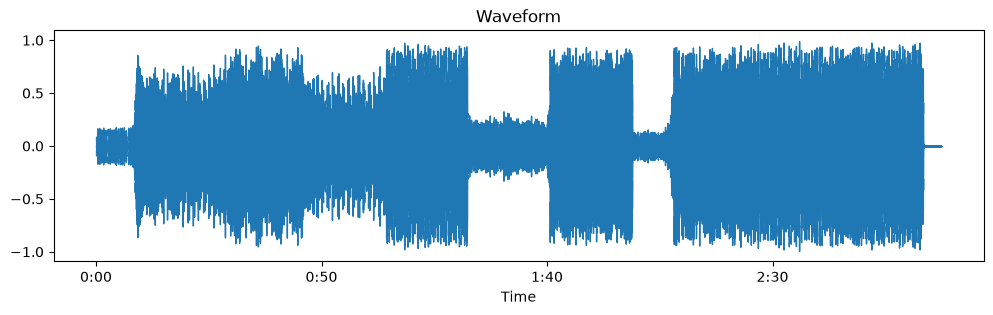

In [3]:
plt.figure(figsize=(12,3))
librosa.display.waveshow(y, sr=sr)
plt.title("Waveform")
plt.show()

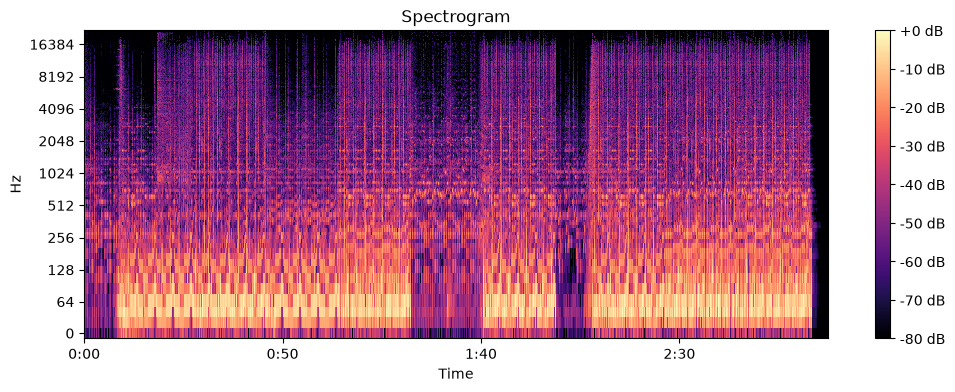

In [ ]:
stft = librosa.stft(y, n_fft=2048, hop_length=512) # samples per window = 2048, overlap between two windows = 512
magnitude = np.abs(stft) # output of fourier transform are complex numbers at each frequency which encodes magnitude and phase offset. We only want magnitude
S = librosa.amplitude_to_db(magnitude, ref=np.max) # scale the magnitudes on a log scale to convert them to decibles
plt.figure(figsize=(12, 4))
librosa.display.specshow(S, sr=sr, hop_length=512, x_axis="time", y_axis="log")
plt.colorbar(format="%+2.0f dB")
plt.title("Spectrogram")
plt.show()

In [5]:
Audio(y, rate=sr)